# Coat — Exploratory Data Analysis & Phase-0 safety gates

Preflight for the MNAR re-ranking run described in `docs/mnar/coat_setup.md` (the what) and
`docs/mnar/coat_implementation_plan.md` (the how). **No repo code is imported here** — the plan calls for a
standalone notebook precisely so that a negative answer costs an afternoon instead of a sweep.

The notebook answers one question: **is Coat worth implementing against?** It runs, in order:

| Step | Gate | Stop condition |
| --- | --- | --- |
| §1 | `coat_setup.md` §2 load-time assertions | any assertion fails → the archive layout changed, every number in the docs must be re-derived |
| §5 | **Gate A** — item-description distinctness | `n_distinct < 120` → stop, a low τ would be an artifact of the item vocabulary |
| §6 | **Gate B** — pool positive rate | outside ~[0.15, 0.85] → k=5 has no headroom |

Everything else is descriptive: what the data looks like, and how much room the protocol actually has.
Gates C (roster health) and D (reference stability) are *not* here — they need fitted policies and belong to
Phase 4.

## 0  Provenance and integrity

**Dataset.** Schnabel, Swaminathan, Singh, Chandak, Joachims — *Recommendations as Treatments: Debiasing
Learning and Evaluation*, ICML 2016. Canonical home: <https://www.cs.cornell.edu/~schnabts/mnar/> (`coat.zip`).
Licence **CC BY-NC** — research use only; record it in the paper's data statement.

**How this copy was obtained.** The canonical Cornell host was unreachable from this machine (the environment's
egress proxy allows only a handful of hosts). The files were instead taken from a complete, original-layout
mirror — [`RyanWangZf/CVIB-Rec`](https://github.com/RyanWangZf/CVIB-Rec) at commit `b640e9c5`, `data/coat/`,
the official code release for *Information Theoretic Counterfactual Learning from MNAR Feedback* (NeurIPS 2020) —
and **cross-checked against a second, independent mirror**,
[`DongHande/AutoDebias`](https://github.com/DongHande/AutoDebias) at commit `39101ad5`, `datasets/coat/`
(AutoDebias, SIGIR 2021). Every numeric value in all five matrices is identical between the two mirrors, and
both carry the original `README.txt` / `ref.txt`. The two copies differ only in trailing whitespace, so the
SHA256s below are of *this* copy, not of the original archive.

> **Action item before publication:** re-download `coat.zip` from the Cornell URL on a machine with open egress
> and confirm the parsed matrices match these hashes. Byte-level equality with the original archive is *not*
> established here; value-level agreement across two independent third-party mirrors is.

In [1]:
from pathlib import Path
import hashlib
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("../data/raw/coat")
SEED = 0
rng = np.random.default_rng(SEED)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
pd.set_option("display.width", 130)

FILES = [
    "train.ascii",
    "test.ascii",
    "propensities.ascii",
    "user_item_features/item_features.ascii",
    "user_item_features/item_features_map.txt",
    "user_item_features/user_features.ascii",
    "user_item_features/user_features_map.txt",
    "README.txt",
    "ref.txt",
]

provenance = pd.DataFrame([
    {"file": f, "bytes": len((RAW / f).read_bytes()),
     "sha256": hashlib.sha256((RAW / f).read_bytes()).hexdigest()}
    for f in FILES
])
provenance

,file,bytes,sha256
0,train.ascii,174000,f9088c6e95fa9a42e8be6a92fc77252b95b969e34ed129...
1,test.ascii,174000,51fa28550f5bedebc6959d0e7b5e242b173c3c8d16317c...
2,propensities.ascii,2175000,a72e3142a413623c4a6b9d20c4f70fcc017e0db67cc3eb...
3,user_item_features/item_features.ascii,19800,72b08cc0766d3e9899231aea90c815b5bb08e07dcfba56...
4,user_item_features/item_features_map.txt,498,2675dfaa38b89a9cbb1997f0cfcd46ed7e0e366dc515d1...
5,user_item_features/user_features.ascii,8120,593b59c63a3f983575d3a770b32158fdfa4e2e4f63aaff...
6,user_item_features/user_features_map.txt,211,3b8c825ad4445d4a46a400629c5fb43c805ff5a7982b2e...
7,README.txt,182,d06ddde2bfb40fa325d8d185af9b4e8b23a90e994ba1ac...
8,ref.txt,64,785f122ed6f4f495021a9c0a40a345481625e42c7b60c6...


In [2]:
print((RAW / "README.txt").read_text())
print("Reference:", (RAW / "ref.txt").read_text().strip())

- train.ascii: Ratings for a subset of self-selected items
- test.ascii: Ratings for a subset of random items
- propensities.ascii: Learned propensities from data in /propensity_data
Reference: Recommendations as Treatments: Debiasing Learning and Evaluation


## 1  Load and the §2 load-time assertions

**One parsing trap, worth stating loudly.** The `*_map.txt` files must be read **line-wise**, not
whitespace-split: two user feature names contain spaces (`age:over 60`, `fashioninterest:not at all`).
Splitting on whitespace yields 18 "names" for a 14-column matrix and silently misaligns every user covariate.

In [3]:
def load_matrix(name: str) -> np.ndarray:
    return np.loadtxt(RAW / name)


def load_names(name: str) -> list[str]:
    # line-wise on purpose: names contain spaces ("age:over 60")
    return (RAW / name).read_text().splitlines()


train = load_matrix("train.ascii")   # self-selected ratings (MNAR half); 0 = not rated
test  = load_matrix("test.ascii")    # uniformly random ratings (MCAR half); 0 = not rated
prop  = load_matrix("propensities.ascii")

item_feat  = load_matrix("user_item_features/item_features.ascii")
user_feat  = load_matrix("user_item_features/user_features.ascii")
item_names = load_names("user_item_features/item_features_map.txt")
user_names = load_names("user_item_features/user_features_map.txt")

N_USERS, N_ITEMS = train.shape
print(f"train {train.shape}   test {test.shape}   propensities {prop.shape}")
print(f"item_features {item_feat.shape} / {len(item_names)} names")
print(f"user_features {user_feat.shape} / {len(user_names)} names")

train (290, 300)   test (290, 300)   propensities (290, 300)
item_features (300, 33) / 33 names
user_features (290, 14) / 14 names


In [4]:
checks = []


def check(name, expected, observed, critical=True):
    ok = bool(expected == observed) if not isinstance(expected, str) else bool(expected == str(observed))
    checks.append({"assertion": name, "expected": expected, "observed": observed,
                   "status": "PASS" if ok else ("FAIL" if critical else "WARN"), "critical": critical})
    return ok


train_counts = (train > 0).sum(axis=1)
test_counts  = (test  > 0).sum(axis=1)
train_vals   = set(np.unique(train[train > 0]).astype(int).tolist())
test_vals    = set(np.unique(test[test > 0]).astype(int).tolist())

check("train.shape == (290, 300)", (290, 300), train.shape)
check("test.shape == (290, 300)", (290, 300), test.shape)
check("propensities.shape == (290, 300)", (290, 300), prop.shape)
check("every user has exactly 24 self-selected ratings", [24], np.unique(train_counts).tolist())
check("every user has exactly 16 random ratings", [16], np.unique(test_counts).tolist())
check("the two halves are disjoint", 0, int(((train > 0) & (test > 0)).sum()))
check("train ratings in {1..5}", {1, 2, 3, 4, 5}, train_vals)
check("test ratings in {1..5}", {1, 2, 3, 4, 5}, test_vals)
check("item_features.shape == (300, 33)", (300, 33), item_feat.shape)
check("user_features.shape == (290, 14)", (290, 14), user_feat.shape)
check("len(item_feature_names) == 33", 33, len(item_names))
check("len(user_feature_names) == 14", 14, len(user_names))
check("self-selected rows total 6,960", 6960, int((train > 0).sum()))
check("random rows total 4,640", 4640, int((test > 0).sum()))

assertions = pd.DataFrame(checks)[["assertion", "expected", "observed", "status"]]
assertions

,assertion,expected,observed,status
0,"train.shape == (290, 300)","(290, 300)","(290, 300)",PASS
1,"test.shape == (290, 300)","(290, 300)","(290, 300)",PASS
2,"propensities.shape == (290, 300)","(290, 300)","(290, 300)",PASS
3,every user has exactly 24 self-selected ratings,[24],[24],PASS
4,every user has exactly 16 random ratings,[16],[16],PASS
5,the two halves are disjoint,0,366,FAIL
6,train ratings in {1..5},"{1, 2, 3, 4, 5}","{1, 2, 3, 4, 5}",PASS
7,test ratings in {1..5},"{1, 2, 3, 4, 5}","{1, 2, 3, 4, 5}",PASS
8,"item_features.shape == (300, 33)","(300, 33)","(300, 33)",PASS
9,"user_features.shape == (290, 14)","(290, 14)","(290, 14)",PASS


In [5]:
failed = [c for c in checks if c["status"] == "FAIL"]
if failed:
    print(f"{len(failed)} of {len(checks)} assertions FAILED:\n")
    for c in failed:
        print(f"  - {c['assertion']}\n      expected {c['expected']!r}, observed {c['observed']!r}")
else:
    print(f"All {len(checks)} load-time assertions passed.")

1 of 14 assertions FAILED:

  - the two halves are disjoint
      expected 0, observed 366


### 1.1  The disjointness assertion fails — 366 cells are in both halves

This is the first real finding, and it contradicts an assumption the plan leans on:
*"all 16 random ratings per user, never trained on — the reference."*

Some participants were randomly shown a coat they had already rated themselves. Those cells appear in **both**
`train.ascii` and `test.ascii`, with the **same** rating in every case.

In [6]:
overlap = (train > 0) & (test > 0)
ov_u, ov_i = np.where(overlap)
n_ov = int(overlap.sum())

print(f"overlapping cells            : {n_ov}  ({n_ov / (test > 0).sum():.2%} of the 4,640 pool cells)")
print(f"ratings identical in overlap : {int((train[overlap] == test[overlap]).sum())} / {n_ov}")
print(f"users affected               : {len(np.unique(ov_u))} of {N_USERS}")
print(f"items affected               : {len(np.unique(ov_i))} of {N_ITEMS}")
print()
per_user_ov = np.bincount(ov_u, minlength=N_USERS)
print("per-user overlap count:")
print(pd.Series(per_user_ov).value_counts().sort_index().rename_axis("cells").to_frame("users").T)

overlapping cells            : 366  (7.89% of the 4,640 pool cells)
ratings identical in overlap : 366 / 366
users affected               : 216 of 290
items affected               : 196 of 300

per-user overlap count:
cells   0    1   2   3  4
users  74  112  65  32  7


**Why it matters.** Under the plan, policies are fitted on the self-selected half and the reference ordering is
computed on the 16-item random pool. For 216 of 290 users, between 1 and 4 of their pool items carry a label the
policy was trained on. That is label leakage straight into the reference — small (7.9% of pool cells) but
directly on the quantity the whole experiment is built to measure.

**Recommended fix — remove the overlap from `train`, not from the pool.** Dropping ≤4 ratings from a user's 24
self-selected rows is cheap and keeps `test_unbiased` intact at a uniform 16 items per user. Dropping them from
the pool instead would make pool sizes ragged (12–16) and shrink the reference by 8%.

In [7]:
pool_wo = test.copy()
pool_wo[overlap] = 0

print("Option A — drop overlap from train (recommended)")
print(f"  train rows      : {int((train > 0).sum())} -> {int(((train > 0) & ~overlap).sum())}")
print(f"  per-user train  : {np.unique(((train > 0) & ~overlap).sum(1)).min()}–"
      f"{np.unique(((train > 0) & ~overlap).sum(1)).max()} (was a flat 24)")
print(f"  pool untouched  : {int((test > 0).sum())} rows, 16 per user")
print()
sizes = pd.Series((pool_wo > 0).sum(axis=1)).value_counts().sort_index()
print("Option B — drop overlap from the pool")
print(f"  pool rows       : {int((test > 0).sum())} -> {int((pool_wo > 0).sum())}")
print(f"  per-user pool   : " + ", ".join(f"{n} items x {c} users" for n, c in sizes.items()))
print(f"  pool P(>=4)     : {(test[test > 0] >= 4).mean():.4f} -> {(pool_wo[pool_wo > 0] >= 4).mean():.4f}")

Option A — drop overlap from train (recommended)
  train rows      : 6960 -> 6594
  per-user train  : 20–24 (was a flat 24)
  pool untouched  : 4640 rows, 16 per user

Option B — drop overlap from the pool
  pool rows       : 4640 -> 4274
  per-user pool   : 12 items x 7 users, 13 items x 32 users, 14 items x 65 users, 15 items x 112 users, 16 items x 74 users
  pool P(>=4)     : 0.1853 -> 0.1799


## 2  The canonical long frame (`coat_setup.md` §3)

Built here to validate the adapter spec before anyone writes `datasets/coat.py`. Item text follows the §4
template, adapted to the attribute names the archive actually uses (`jackettype`, `color`, `onfrontpage`).

In [8]:
def group_index(names: list[str]) -> dict[str, list[int]]:
    groups: dict[str, list[int]] = {}
    for i, n in enumerate(names):
        groups.setdefault(n.split(":", 1)[0], []).append(i)
    return groups


ITEM_GROUPS = group_index(item_names)
USER_GROUPS = group_index(user_names)

print("item groups:", {k: len(v) for k, v in ITEM_GROUPS.items()})
print("user groups:", {k: len(v) for k, v in USER_GROUPS.items()})

# every group must be a genuine one-hot, otherwise argmax below is a silent lie
for label, feat, groups in [("item", item_feat, ITEM_GROUPS), ("user", user_feat, USER_GROUPS)]:
    for g, idx in groups.items():
        sums = np.unique(feat[:, idx].sum(axis=1))
        assert sums.tolist() == [1.0], f"{label} group {g} is not one-hot: row sums {sums}"
print("\nall covariate groups are exact one-hots")

item groups: {'gender': 2, 'jackettype': 16, 'color': 13, 'onfrontpage': 2}
user groups: {'gender': 2, 'age': 6, 'location': 3, 'fashioninterest': 3}

all covariate groups are exact one-hots


In [9]:
def attr(feat, names, groups, row, group):
    # value of a one-hot covariate group for one row: attr(..., 12, "color") -> "navy"
    idx = groups[group]
    return names[idx[int(np.argmax(feat[row, idx]))]].split(":", 1)[1]


def item_attrs(i: int) -> dict[str, str]:
    return {g: attr(item_feat, item_names, ITEM_GROUPS, i, g) for g in ITEM_GROUPS}


def item_title(i: int) -> str:
    a = item_attrs(i)
    promoted = "promoted " if a["onfrontpage"] == "yes" else ""
    return f"{promoted}{a['gender']}'s {a['jackettype']} coat in {a['color']}"


def item_genres(i: int) -> str:
    a = item_attrs(i)
    parts = [a["gender"], a["jackettype"], a["color"]]
    if a["onfrontpage"] == "yes":
        parts.append("promoted")
    return "|".join(parts)


items = pd.DataFrame({
    "item_id": np.arange(N_ITEMS),
    **{g: [item_attrs(i)[g] for i in range(N_ITEMS)] for g in ITEM_GROUPS},
    "item_title": [item_title(i) for i in range(N_ITEMS)],
    "item_genres": [item_genres(i) for i in range(N_ITEMS)],
})
items.head(8)

,item_id,gender,jackettype,color,onfrontpage,item_title,item_genres
0,0,men,bomber,other,yes,promoted men's bomber coat in other,men|bomber|other|promoted
1,1,men,insulated,blue,no,men's insulated coat in blue,men|insulated|blue
2,2,men,other,olive,no,men's other coat in olive,men|other|olive
3,3,men,rain,gray,no,men's rain coat in gray,men|rain|gray
4,4,men,other,black,no,men's other coat in black,men|other|black
5,5,men,shells,beige,no,men's shells coat in beige,men|shells|beige
6,6,men,field,beige,no,men's field coat in beige,men|field|beige
7,7,men,parkas,navy,no,men's parkas coat in navy,men|parkas|navy


In [10]:
def long_frame(mat, source):
    u, i = np.where(mat > 0)
    return pd.DataFrame({
        "user_id": u, "item_id": i, "rating": mat[u, i].astype(int), "source": source,
        "propensity": prop[u, i] if source == "self_selected" else np.nan,
    })


interactions = pd.concat([long_frame(train, "self_selected"), long_frame(test, "random")], ignore_index=True)
interactions["target_interact"] = 1
interactions["target_like_ge4"] = (interactions["rating"] >= 4).astype(int)
interactions = interactions.merge(items[["item_id", "item_title", "item_genres"]], on="item_id", how="left")

print(f"rows                       : {len(interactions):,}   (spec says 11,600)")
print(f"distinct (user, item) pairs: {interactions[['user_id', 'item_id']].drop_duplicates().shape[0]:,}"
      f"   <- {len(interactions) - interactions[['user_id', 'item_id']].drop_duplicates().shape[0]} pairs "
      f"appear in both halves")
print()
print(interactions.groupby("source").agg(rows=("rating", "size"), mean_rating=("rating", "mean"),
                                         p_like=("target_like_ge4", "mean")).round(4))
interactions.head()

rows                       : 11,600   (spec says 11,600)
distinct (user, item) pairs: 11,234   <- 366 pairs appear in both halves

               rows  mean_rating  p_like
source                                  
random         4640       2.2289  0.1853
self_selected  6960       2.6115  0.2737


,user_id,item_id,rating,source,propensity,target_interact,target_like_ge4,item_title,item_genres
0,0,72,2,self_selected,0.015305,1,0,men's shells coat in green,men|shells|green
1,0,136,2,self_selected,0.019493,1,0,men's bomber coat in brown,men|bomber|brown
2,0,150,3,self_selected,0.198479,1,0,women's cropped coat in black,women|cropped|black
3,0,171,3,self_selected,0.183878,1,0,women's fleece coat in purple,women|fleece|purple
4,0,188,3,self_selected,0.149617,1,0,women's trench coat in gray,women|trench|gray


In [11]:
users = pd.DataFrame({
    "user_id": np.arange(N_USERS),
    "user_gender": [attr(user_feat, user_names, USER_GROUPS, u, "gender") for u in range(N_USERS)],
    "user_age_group": [attr(user_feat, user_names, USER_GROUPS, u, "age") for u in range(N_USERS)],
    "user_location": [attr(user_feat, user_names, USER_GROUPS, u, "location") for u in range(N_USERS)],
    "user_fashion_awareness": [attr(user_feat, user_names, USER_GROUPS, u, "fashioninterest") for u in range(N_USERS)],
})
users["persona"] = users.apply(
    lambda r: (f"A {r.user_age_group} {r.user_gender} shopper from a {r.user_location} area "
               f"who is {r.user_fashion_awareness} interested in fashion."), axis=1)
print(users["persona"].iloc[0])
print(users["persona"].iloc[7])
users.head(5)

A 20-30 women shopper from a urban area who is very interested in fashion.
A 40-50 women shopper from a urban area who is moderately interested in fashion.


,user_id,user_gender,user_age_group,user_location,user_fashion_awareness,persona
0,0,women,20-30,urban,very,A 20-30 women shopper from a urban area who is...
1,1,women,30-40,suburban,moderately,A 30-40 women shopper from a suburban area who...
2,2,women,20-30,suburban,moderately,A 20-30 women shopper from a suburban area who...
3,3,women,40-50,urban,moderately,A 40-50 women shopper from a urban area who is...
4,4,women,30-40,suburban,moderately,A 30-40 women shopper from a suburban area who...


## 3  The MNAR signature — is the bias actually there?

Everything downstream assumes the self-selected half is *meaningfully* biased relative to the random half.
If the two halves had the same rating distribution there would be no bias to correct and no experiment to run.

In [12]:
sel = train[train > 0]
ran = test[test > 0]

dist = pd.DataFrame({
    "self_selected": pd.Series(sel).value_counts(normalize=True).sort_index(),
    "random_pool":   pd.Series(ran).value_counts(normalize=True).sort_index(),
}).rename_axis("rating")
dist["lift"] = dist["self_selected"] / dist["random_pool"]

print(f"mean rating   self-selected {sel.mean():.3f}   random {ran.mean():.3f}   "
      f"(gap {sel.mean() - ran.mean():+.3f})")
print(f"P(rating>=4)  self-selected {(sel >= 4).mean():.4f}   random {(ran >= 4).mean():.4f}   "
      f"(x{(sel >= 4).mean() / (ran >= 4).mean():.2f})")
dist.round(4)

mean rating   self-selected 2.611   random 2.229   (gap +0.383)
P(rating>=4)  self-selected 0.2737   random 0.1853   (x1.48)


,self_selected,random_pool,lift
rating,,,
1.0,0.2731,0.4050,0.6745
2.0,0.2065,0.1938,1.0656
3.0,0.2467,0.2159,1.1424
4.0,0.1832,0.1381,1.3261
5.0,0.0905,0.0472,1.9178


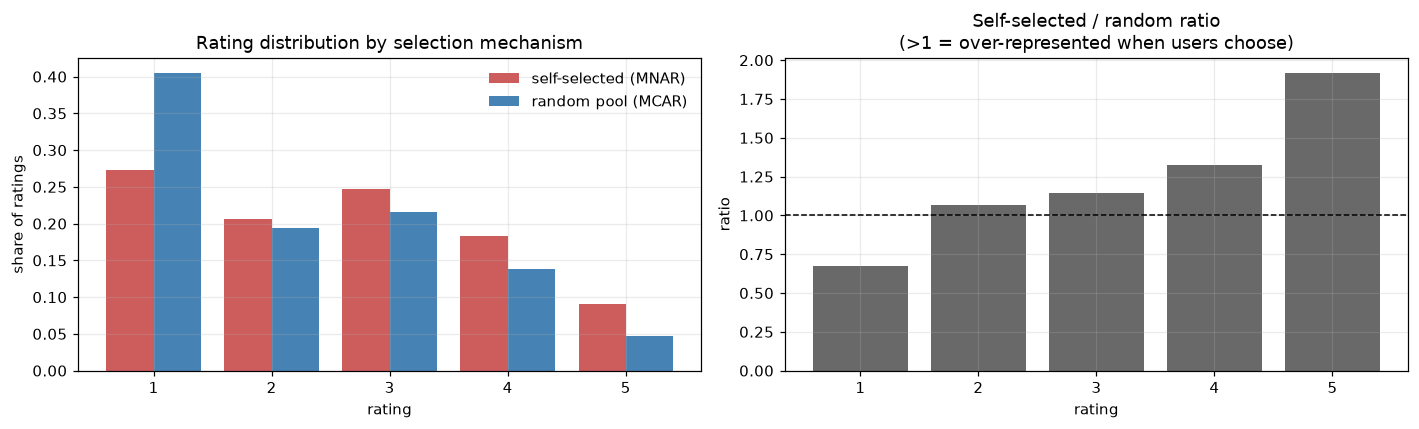

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

x = np.arange(1, 6)
w = 0.4
axes[0].bar(x - w/2, dist["self_selected"], w, label="self-selected (MNAR)", color="indianred")
axes[0].bar(x + w/2, dist["random_pool"], w, label="random pool (MCAR)", color="steelblue")
axes[0].set_title("Rating distribution by selection mechanism")
axes[0].set_xlabel("rating"); axes[0].set_ylabel("share of ratings"); axes[0].set_xticks(x)
axes[0].legend(frameon=False)

axes[1].bar(x, dist["lift"], color="dimgray")
axes[1].axhline(1.0, color="black", lw=1, ls="--")
axes[1].set_title("Self-selected / random ratio\n(>1 = over-represented when users choose)")
axes[1].set_xlabel("rating"); axes[1].set_ylabel("ratio"); axes[1].set_xticks(x)

plt.tight_layout(); plt.show()

### 3.1  Exposure: skewed when users choose, flat when the system assigns

A second, independent view of the same bias — and a sanity check that the random half really is MCAR.
If pool assignment were uniform over the 300 coats, per-item pool counts should look like a multinomial draw.

In [14]:
exposure_self = (train > 0).sum(axis=0)
exposure_pool = (test  > 0).sum(axis=0)

sim = np.array([np.bincount(rng.choice(N_ITEMS, 16, replace=False), minlength=N_ITEMS)
                for _ in range(N_USERS)]).sum(axis=0)

summary = pd.DataFrame({
    "self-selected": [exposure_self.mean(), exposure_self.std(), exposure_self.min(), exposure_self.max()],
    "random pool":   [exposure_pool.mean(), exposure_pool.std(), exposure_pool.min(), exposure_pool.max()],
    "simulated uniform": [sim.mean(), sim.std(), sim.min(), sim.max()],
}, index=["mean", "sd", "min", "max"]).round(2)
print("Per-item exposure counts across the 300 coats\n")
print(summary)
print(f"\nGini-ish concentration: top-10% of items hold "
      f"{np.sort(exposure_self)[-30:].sum() / exposure_self.sum():.1%} of self-selected ratings "
      f"vs {np.sort(exposure_pool)[-30:].sum() / exposure_pool.sum():.1%} of pool ratings")

Per-item exposure counts across the 300 coats

      self-selected  random pool  simulated uniform
mean          23.20        15.47              15.47
sd            13.67         3.82               3.79
min            5.00         5.00               6.00
max           88.00        29.00              26.00

Gini-ish concentration: top-10% of items hold 23.6% of self-selected ratings vs 14.6% of pool ratings


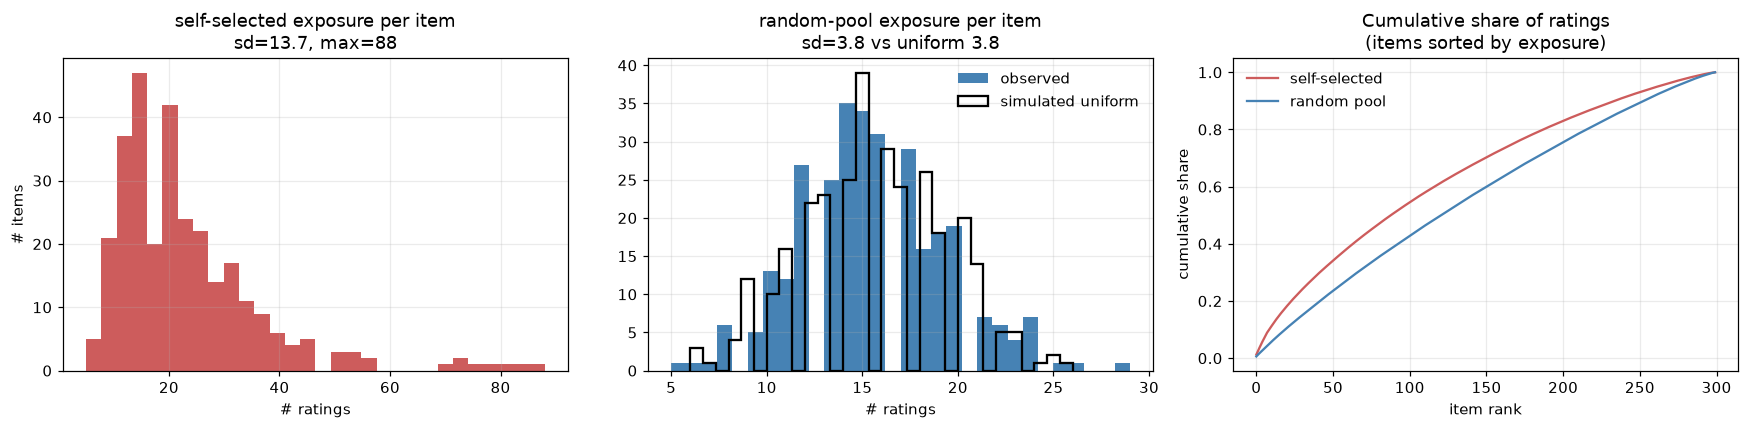

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(exposure_self, bins=30, color="indianred", edgecolor="none")
axes[0].set_title(f"self-selected exposure per item\nsd={exposure_self.std():.1f}, max={exposure_self.max()}")
axes[0].set_xlabel("# ratings"); axes[0].set_ylabel("# items")

axes[1].hist(exposure_pool, bins=30, color="steelblue", edgecolor="none", label="observed")
axes[1].hist(sim, bins=30, histtype="step", color="black", lw=1.5, label="simulated uniform")
axes[1].set_title(f"random-pool exposure per item\nsd={exposure_pool.std():.1f} vs uniform {sim.std():.1f}")
axes[1].set_xlabel("# ratings"); axes[1].legend(frameon=False)

order = np.argsort(-exposure_self)
axes[2].plot(np.cumsum(exposure_self[order]) / exposure_self.sum(), color="indianred", label="self-selected")
axes[2].plot(np.cumsum(exposure_pool[np.argsort(-exposure_pool)]) / exposure_pool.sum(),
             color="steelblue", label="random pool")
axes[2].set_title("Cumulative share of ratings\n(items sorted by exposure)")
axes[2].set_xlabel("item rank"); axes[2].set_ylabel("cumulative share"); axes[2].legend(frameon=False)

plt.tight_layout(); plt.show()

### 3.2  Does popularity predict *unbiased* quality?

This is a cheap early read on the Gate C risk. `Popularity` is the policy the plan requires to separate from
`Random`; if self-selected exposure carries no signal about pool quality, that separation will be thin.

items with >=8 pool observations: 297 of 300
corr(self-selected exposure, unbiased P(>=4))      = +0.196
corr(self-selected liked-count, unbiased P(>=4))   = +0.440


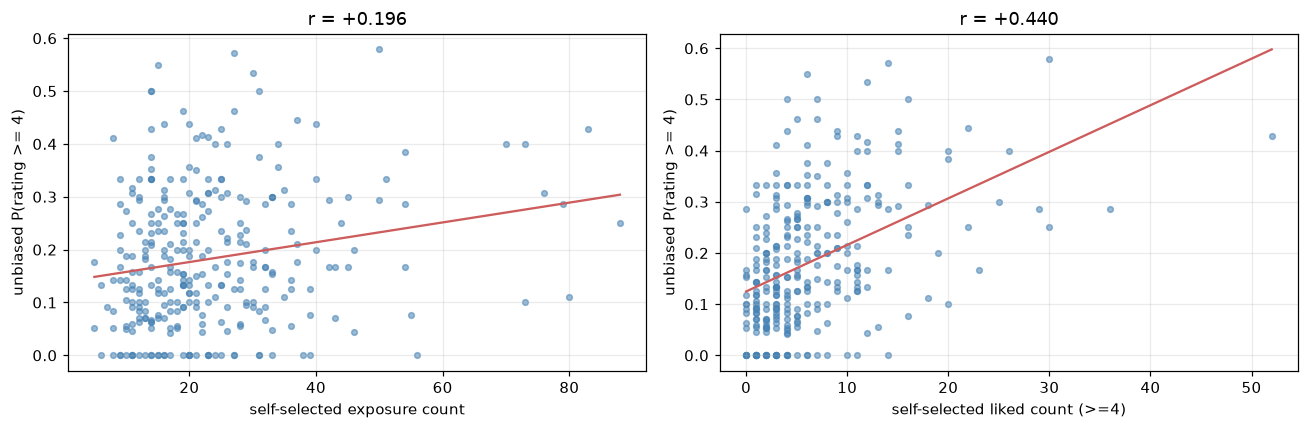

In [16]:
pool_mask = test > 0
item_pool_n = pool_mask.sum(axis=0)
item_pool_like = np.where(item_pool_n > 0, (test >= 4).sum(axis=0) / np.maximum(item_pool_n, 1), np.nan)

ok = item_pool_n >= 8   # items with enough pool observations for a stable rate
r_exposure = np.corrcoef(exposure_self[ok], item_pool_like[ok])[0, 1]
liked_self = (train >= 4).sum(axis=0)
r_liked = np.corrcoef(liked_self[ok], item_pool_like[ok])[0, 1]

print(f"items with >=8 pool observations: {ok.sum()} of {N_ITEMS}")
print(f"corr(self-selected exposure, unbiased P(>=4))      = {r_exposure:+.3f}")
print(f"corr(self-selected liked-count, unbiased P(>=4))   = {r_liked:+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, xs, name, r in [(axes[0], exposure_self, "self-selected exposure count", r_exposure),
                        (axes[1], liked_self, "self-selected liked count (>=4)", r_liked)]:
    ax.scatter(xs[ok], item_pool_like[ok], s=14, alpha=0.55, color="steelblue")
    m, b = np.polyfit(xs[ok], item_pool_like[ok], 1)
    xr = np.linspace(xs[ok].min(), xs[ok].max(), 50)
    ax.plot(xr, m * xr + b, color="indianred", lw=1.5)
    ax.set_xlabel(name); ax.set_ylabel("unbiased P(rating >= 4)")
    ax.set_title(f"r = {r:+.3f}")
plt.tight_layout(); plt.show()

## 4  Propensities

`propensities.ascii` is dense (all 87,000 cells) and holds Schnabel et al.'s *estimated* probability of
observation for the self-selected half — fitted with logistic regression on covariates, **not logged**. Any
`rank_biased_ips` competitor built on these inherits that model's error, which the paper must state.

range          : [0.0025, 0.6903]   NaNs: 0
row sums       : mean 24.01  (24 would mean 'calibrated to the observed count')
observed cells : mean p 0.1652   median 0.1387
unobserved     : mean p 0.0726   median 0.0383
below clip 0.01: 0.76% of observed cells (53 cells) would be clipped by the plan's p_min
max 1/p on observed cells: 1.4 .. 100.0


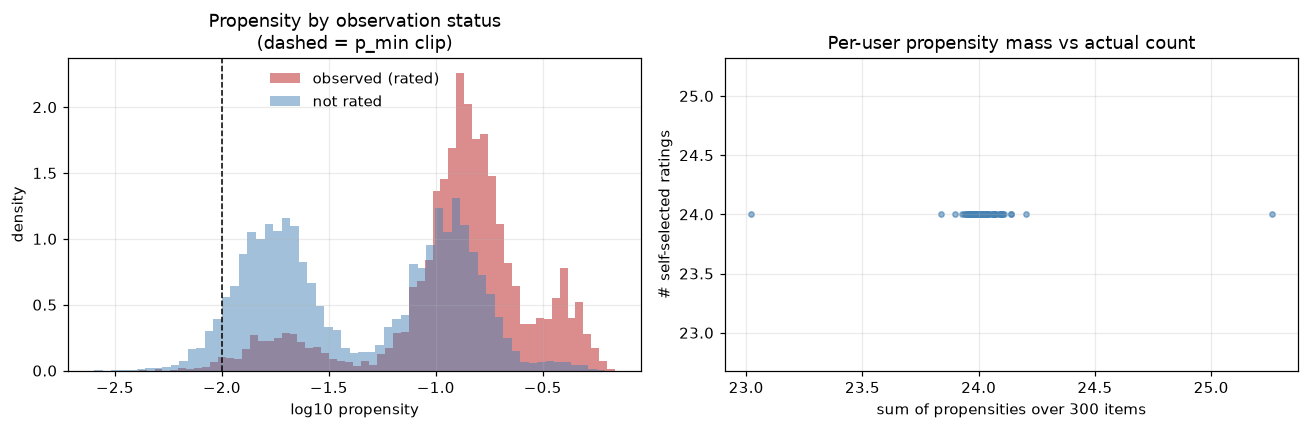

In [17]:
p_obs = prop[train > 0]
p_unobs = prop[train == 0]

print(f"range          : [{prop.min():.4f}, {prop.max():.4f}]   NaNs: {int(np.isnan(prop).sum())}")
print(f"row sums       : mean {prop.sum(axis=1).mean():.2f}  (24 would mean 'calibrated to the observed count')")
print(f"observed cells : mean p {p_obs.mean():.4f}   median {np.median(p_obs):.4f}")
print(f"unobserved     : mean p {p_unobs.mean():.4f}   median {np.median(p_unobs):.4f}")
print(f"below clip 0.01: {(p_obs < 0.01).mean():.2%} of observed cells "
      f"({int((p_obs < 0.01).sum())} cells) would be clipped by the plan's p_min")
print(f"max 1/p on observed cells: {1 / np.maximum(p_obs, 0.01).max():.1f} .. {1 / np.maximum(p_obs, 0.01).min():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(p_obs), bins=60, color="indianred", alpha=0.7, density=True, label="observed (rated)")
axes[0].hist(np.log10(p_unobs), bins=60, color="steelblue", alpha=0.5, density=True, label="not rated")
axes[0].axvline(np.log10(0.01), color="black", ls="--", lw=1)
axes[0].set_xlabel("log10 propensity"); axes[0].set_ylabel("density")
axes[0].set_title("Propensity by observation status\n(dashed = p_min clip)"); axes[0].legend(frameon=False)

axes[1].scatter(prop.sum(axis=1), (train > 0).sum(axis=1), s=12, alpha=0.6, color="steelblue")
axes[1].set_xlabel("sum of propensities over 300 items"); axes[1].set_ylabel("# self-selected ratings")
axes[1].set_title("Per-user propensity mass vs actual count")
plt.tight_layout(); plt.show()

## 5  Gate A — item-description distinctness

> `n_distinct >= 200` proceed · `120 <= n_distinct < 200` proceed **and report the collision rate** ·
> `n_distinct < 120` **stop**

With 33 binary attributes in four one-hot groups, an item's verbalization is a function of exactly one tuple:
`(gender, jackettype, color, onfrontpage)`. So `n_distinct` is a property of the *data*, not of the phrasing —
rewording the template cannot raise it. Only adding information (an index, a pseudo-brand) can.

In [18]:
tuples_full = items[["gender", "jackettype", "color", "onfrontpage"]].apply(tuple, axis=1)
tuples_visual = items[["gender", "jackettype", "color"]].apply(tuple, axis=1)

n_distinct = items["item_title"].nunique()
n_distinct_visual = tuples_visual.nunique()

print(f"attribute vocabulary: {len(ITEM_GROUPS['gender'])} genders x "
      f"{len(ITEM_GROUPS['jackettype'])} types x {len(ITEM_GROUPS['color'])} colors x 2 promoted "
      f"= {2 * 16 * 13 * 2:,} expressible descriptions")
print()
print(f"GATE A  n_distinct (incl. 'promoted')        = {n_distinct} of {N_ITEMS}")
print(f"        n_distinct (visual attributes only)  = {n_distinct_visual} of {N_ITEMS}")

band = ("STOP" if n_distinct < 120 else "PROCEED WITH DISCLOSURE" if n_distinct < 200 else "PROCEED")
print(f"\n        verdict: {band}")

attribute vocabulary: 2 genders x 16 types x 13 colors x 2 promoted = 832 expressible descriptions

GATE A  n_distinct (incl. 'promoted')        = 165 of 300
        n_distinct (visual attributes only)  = 155 of 300

        verdict: PROCEED WITH DISCLOSURE


In [19]:
counts = items["item_title"].value_counts()
colliding_items = int(counts[counts > 1].sum())

print(f"items sharing their description with >=1 other: {colliding_items} of {N_ITEMS} "
      f"({colliding_items / N_ITEMS:.1%})")
print(f"largest collision group: {counts.iloc[0]} items -> {counts.index[0]!r}\n")
print(counts.head(8).rename_axis("item_title").to_frame("n_items"))

items sharing their description with >=1 other: 203 of 300 (67.7%)
largest collision group: 9 items -> "men's other coat in black"

                                 n_items
item_title                              
men's other coat in black              9
women's insulated coat in other        8
women's insulated coat in black        7
women's parkas coat in black           6
women's other coat in other            6
men's parkas coat in black             5
women's bomber coat in other           5
women's other coat in beige            5


**The number that actually matters** is not the catalog-level collision rate but how often the simulator is
asked to rank two items it *cannot tell apart* — and how often those look-alikes carry different labels. Those
are provably uninformed decisions, and they bound the achievable τ from above.

In [20]:
title_of = items["item_title"].to_numpy()
label = (test >= 4)

pools_with_collision = 0
pairs_total = pairs_tied = pairs_tied_split = 0

for u in range(N_USERS):
    pool = np.where(test[u] > 0)[0]
    titles = title_of[pool]
    groups: dict[str, list[int]] = {}
    for it, t in zip(pool, titles):
        groups.setdefault(t, []).append(it)
    dup = {t: g for t, g in groups.items() if len(g) > 1}
    if dup:
        pools_with_collision += 1
    pairs_total += len(pool) * (len(pool) - 1) // 2
    for t, g in dup.items():
        for a, b in combinations(g, 2):
            pairs_tied += 1
            if label[u, a] != label[u, b]:
                pairs_tied_split += 1

print(f"pools containing >=1 look-alike pair : {pools_with_collision} of {N_USERS} "
      f"({pools_with_collision / N_USERS:.1%})")
print(f"look-alike pairs within pools        : {pairs_tied:,} of {pairs_total:,} candidate pairs "
      f"({pairs_tied / pairs_total:.2%})")
print(f"  ...of which the labels disagree    : {pairs_tied_split:,} "
      f"({pairs_tied_split / max(pairs_tied, 1):.1%} of look-alike pairs, "
      f"{pairs_tied_split / pairs_total:.2%} of all pairs)")
print()
print("Read: the last line is the share of within-pool comparisons the simulator provably cannot get right,")
print("because the two items are the same string to it but different labels in the reference.")

pools containing >=1 look-alike pair : 159 of 290 (54.8%)
look-alike pairs within pools        : 201 of 34,800 candidate pairs (0.58%)
  ...of which the labels disagree    : 47 (23.4% of look-alike pairs, 0.14% of all pairs)

Read: the last line is the share of within-pool comparisons the simulator provably cannot get right,
because the two items are the same string to it but different labels in the reference.


## 6  Gate B — pool positive rate and k=5 headroom

> outside ~[0.15, 0.85] → revisit k or the threshold before building anything

In [21]:
K = 5
pool_positive_rate = (ran >= 4).mean()
L = (test >= 4).sum(axis=1)   # positives among each user's 16 pool items

print(f"GATE B  P(rating >= 4 | pool cell) = {pool_positive_rate:.4f}")
print(f"        band [0.15, 0.85] -> {'PASS' if 0.15 <= pool_positive_rate <= 0.85 else 'FAIL'}"
      f"   (margin to the lower edge: {pool_positive_rate - 0.15:+.4f})")
print()
print(f"L = positives among 16: mean {L.mean():.2f}, median {np.median(L):.0f}, "
      f"max {L.max()}")
print(f"  users with L = 0 : {(L == 0).sum()} ({(L == 0).mean():.1%})  <- contribute zero signal at any k")
print(f"  users with L >= {K}: {(L >= K).sum()} ({(L >= K).mean():.1%})  <- a perfect slate is achievable")
print()
print(pd.Series(L).value_counts().sort_index().rename_axis("L").to_frame("users").T)

GATE B  P(rating >= 4 | pool cell) = 0.1853
        band [0.15, 0.85] -> PASS   (margin to the lower edge: +0.0353)

L = positives among 16: mean 2.97, median 2, max 14
  users with L = 0 : 53 (18.3%)  <- contribute zero signal at any k
  users with L >= 5: 66 (22.8%)  <- a perfect slate is achievable

L      0   1   2   3   4   5   6   7   8   9   10  11  13  14
users  53  56  50  43  22  20  11  10   8   2   6   5   2   2


In [22]:
thresholds = pd.DataFrame([
    {"threshold": f"rating >= {t}",
     "pool P(pos)": (ran >= t).mean(),
     "mean L / 16": (test >= t).sum(axis=1).mean(),
     "users with L=0": ((test >= t).sum(axis=1) == 0).mean(),
     "oracle@5": np.minimum((test >= t).sum(axis=1), K).mean() / K,
     "random@5": ((test >= t).sum(axis=1) / 16).mean(),
     "gate B": "PASS" if 0.15 <= (ran >= t).mean() <= 0.85 else "FAIL"}
    for t in (3, 4, 5)
]).set_index("threshold")
print("Threshold sensitivity — the >=3 fallback from coat_setup.md §6 is healthier on every axis:\n")
thresholds.round(4)

Threshold sensitivity — the >=3 fallback from coat_setup.md §6 is healthier on every axis:



,pool P(pos),mean L / 16,users with L=0,oracle@5,random@5,gate B
threshold,,,,,,
rating >= 3,0.4013,6.4207,0.0310,0.8021,0.4013,PASS
rating >= 4,0.1853,2.9655,0.1828,0.4848,0.1853,PASS
rating >= 5,0.0472,0.7552,0.6517,0.1366,0.0472,FAIL


### 6.1  How much room is there for policies to differ?

The reference utility is `mean(rating >= 4)` over each policy's top-5 of the 16-item pool. The interval any
policy can occupy runs from the *anti-oracle* (worst legal slate) to the *oracle* (best legal slate); a random
re-ranker sits at the pool positive rate. If that interval is narrow, six policies cannot separate and Gate C
will fail in Phase 4 — so this is the cheapest available forecast of the run's main risk.

In [23]:
oracle = np.minimum(L, K).mean() / K
anti   = np.maximum(L - (16 - K), 0).mean() / K
random_u = (L / 16).mean()

# a trivial popularity re-ranker, seeded tie-breaks (never by item id)
def rerank_utility(score: np.ndarray, k: int = K) -> float:
    us = []
    for u in range(N_USERS):
        pool = np.where(test[u] > 0)[0]
        order = pool[np.lexsort((rng.random(len(pool)), -score[pool]))]
        us.append((test[u, order[:k]] >= 4).mean())
    return float(np.mean(us))

u_exposure = rerank_utility(exposure_self.astype(float))
u_liked = rerank_utility(liked_self.astype(float))
u_random = rerank_utility(rng.random(N_ITEMS))

headroom = pd.DataFrame({
    "utility@5": [anti, u_random, random_u, u_exposure, u_liked, oracle],
    "note": ["worst legal slate", "seeded random re-ranker", "expected value of a random re-ranker",
             "rank by self-selected exposure count", "rank by self-selected liked count", "best legal slate"],
}, index=["anti-oracle", "random (realised)", "random (expected)", "popularity: exposure",
          "popularity: liked", "oracle"]).round(4)
print(f"absolute headroom oracle - random = {oracle - random_u:.4f}")
print(f"share of headroom taken by a trivial liked-count heuristic = "
      f"{(u_liked - random_u) / (oracle - random_u):.1%}\n")
headroom

absolute headroom oracle - random = 0.2995
share of headroom taken by a trivial liked-count heuristic = 24.9%



,utility@5,note
anti-oracle,0.0069,worst legal slate
random (realised),0.1993,seeded random re-ranker
random (expected),0.1853,expected value of a random re-ranker
popularity: exposure,0.2110,rank by self-selected exposure count
popularity: liked,0.2600,rank by self-selected liked count
oracle,0.4848,best legal slate


### 6.2  A dry run of Gate C, using heuristics instead of fitted policies

Gate C asks whether policy utilities separate under a **user-level bootstrap**, and requires at minimum that
Popularity beat Random. Both popularity variants above are computable without fitting anything, so the gate's
own machinery can be rehearsed now — B = 2,000 resamples of the 290 participants, resampling *users* (slots are
clustered within users, so slot-level resampling would understate every CI).

Two caveats on what this does and does not forecast. It is a *paired* comparison on the same users, which is
easier to call than two independent CIs; and real fitted policies will sit closer together than these
heuristics do. Read it as an upper bound on how well Phase 4 can go, not as a prediction of it.

In [24]:
def rerank_user_utilities(score: np.ndarray, k: int = K) -> np.ndarray:
    # per-user utility@k, seeded tie-breaks; returns 290 values rather than their mean
    out = np.empty(N_USERS)
    for u in range(N_USERS):
        pool = np.where(test[u] > 0)[0]
        order = pool[np.lexsort((rng.random(len(pool)), -score[pool]))]
        out[u] = (test[u, order[:k]] >= 4).mean()
    return out


util = {
    "random": rerank_user_utilities(rng.random(N_ITEMS)),
    "popularity: exposure": rerank_user_utilities(exposure_self.astype(float)),
    "popularity: liked": rerank_user_utilities(liked_self.astype(float)),
}

B = 2000
boot_idx = rng.integers(0, N_USERS, size=(B, N_USERS))
boot = {name: v[boot_idx].mean(axis=1) for name, v in util.items()}

rand_lo, rand_hi = np.percentile(boot["random"], [2.5, 97.5])

rows = []
for name, v in util.items():
    lo, hi = np.percentile(boot[name], [2.5, 97.5])
    row = {"policy": name, "utility@5": v.mean(), "ci95_lo": lo, "ci95_hi": hi}
    if name != "random":
        d = boot[name] - boot["random"]
        dlo, dhi = np.percentile(d, [2.5, 97.5])
        row |= {"vs random": v.mean() - util["random"].mean(), "diff_lo": dlo, "diff_hi": dhi,
                "paired test": "separates" if dlo > 0 else "no",
                "non-overlapping CIs": "separates" if lo > rand_hi else "no"}
    rows.append(row)

gate_c_dry = pd.DataFrame(rows).set_index("policy")
print(f"user-level bootstrap, B = {B:,}\n")
gate_c_dry.round(4)

user-level bootstrap, B = 2,000



,utility@5,ci95_lo,ci95_hi,vs random,diff_lo,diff_hi,paired test,non-overlapping CIs
policy,,,,,,,,
random,0.1869,0.1614,0.2131,NaN,NaN,NaN,NaN,NaN
popularity: exposure,0.2131,0.1862,0.2400,0.0262,0.0041,0.0469,separates,no
popularity: liked,0.2572,0.2276,0.2869,0.0703,0.0483,0.0917,separates,separates


**The two criteria disagree, and the plan picked the less powerful one.** Exposure-popularity beats Random on the
paired test — the bootstrap CI of the *difference* excludes zero — while its marginal CI still overlaps
Random's. Marginal CIs throw away the pairing: both policies are scored on the same 290 participants, and most
of the width of each marginal CI is participant variation that is common to both and cancels in the difference.

`coat_implementation_plan.md` §5 states Gate C as "non-overlapping 95% CIs". On 290 users that is needlessly
conservative and will fail policies that are genuinely ordered. **Recommend restating Gate C as a paired
bootstrap of the difference** (resampling users, recomputing both utilities within each resample), which is
also exactly what the headline `delta_tau` CI already does in §7 of the plan.

In [25]:
draws = np.array([rerank_utility(rng.random(N_ITEMS)) for _ in range(200)])
noise_sd = draws.std()
ci_halfwidth = (np.percentile(boot["random"], 97.5) - np.percentile(boot["random"], 2.5)) / 2

print(f"scale reference — two different noise sources:")
print(f"  sd of a signal-free re-ranker over 200 seeds : {noise_sd:.4f}  (which items it happens to pick)")
print(f"  half-width of the 95% CI over participants   : {ci_halfwidth:.4f}  (which 290 people were sampled)")
print(f"  the full oracle-to-random span               : {oracle - random_u:.4f}")
print()
print(f"So the span policies must fit inside is ~{(oracle - random_u) / ci_halfwidth:.0f}x the participant-level")
print(f"CI half-width. That is workable — but only if the policies actually spread out across it.")

scale reference — two different noise sources:
  sd of a signal-free re-ranker over 200 seeds : 0.0099  (which items it happens to pick)
  half-width of the 95% CI over participants   : 0.0259  (which 290 people were sampled)
  the full oracle-to-random span               : 0.2995

So the span policies must fit inside is ~12x the participant-level
CI half-width. That is workable — but only if the policies actually spread out across it.


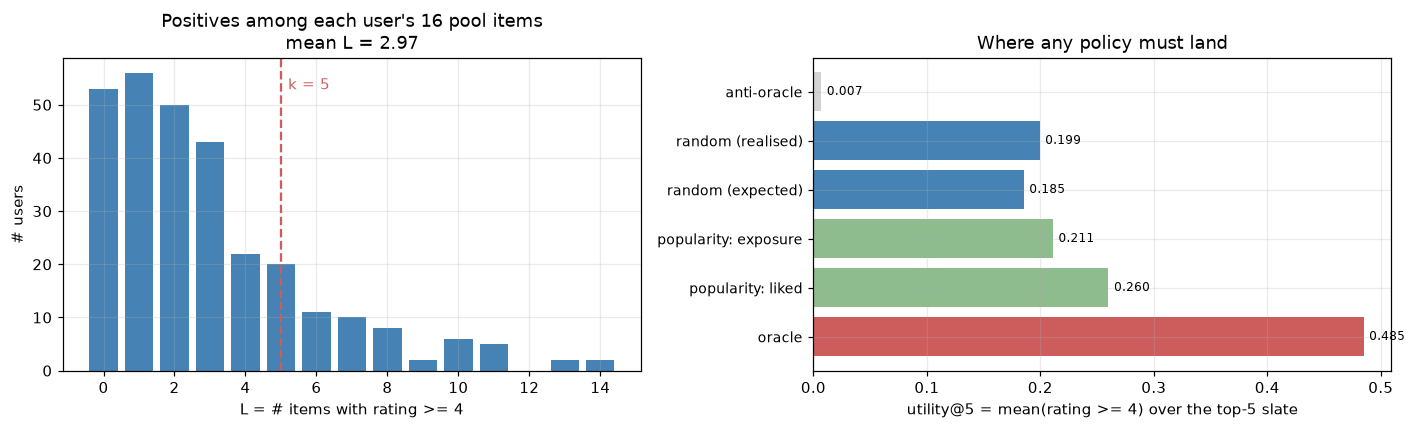

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(np.arange(L.max() + 1), np.bincount(L, minlength=L.max() + 1), color="steelblue")
axes[0].axvline(K, color="indianred", ls="--", lw=1.5)
axes[0].text(K + 0.2, axes[0].get_ylim()[1] * 0.9, f"k = {K}", color="indianred")
axes[0].set_title(f"Positives among each user's 16 pool items\nmean L = {L.mean():.2f}")
axes[0].set_xlabel("L = # items with rating >= 4"); axes[0].set_ylabel("# users")

vals = headroom["utility@5"]
colors = ["lightgray", "steelblue", "steelblue", "darkseagreen", "darkseagreen", "indianred"]
axes[1].barh(range(len(vals)), vals, color=colors)
axes[1].set_yticks(range(len(vals))); axes[1].set_yticklabels(vals.index, fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlabel("utility@5 = mean(rating >= 4) over the top-5 slate")
axes[1].set_title("Where any policy must land")
for i, v in enumerate(vals):
    axes[1].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

## 7  Participants and covariates

Inputs to the Agent4Rec persona path, and a check on whether 290 users are demographically lopsided enough for
persona-conditioned scoring to matter.

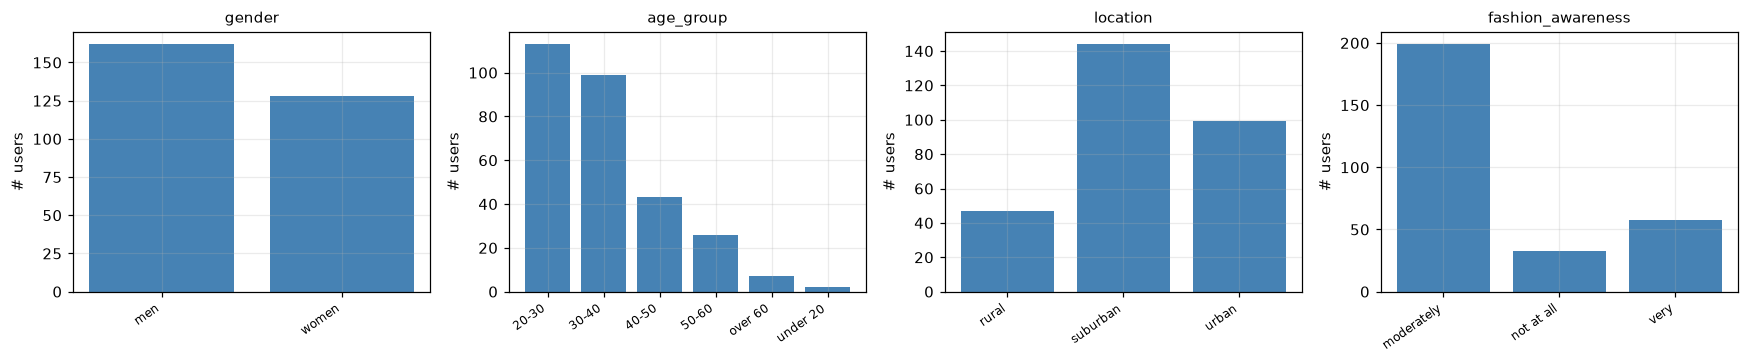

Per-user counts (the fitting signal available to every policy):

       n_self_selected  n_pool  n_train_positives  L_pool_positives
count            290.0   290.0             290.00            290.00
mean              24.0    16.0               6.57              2.97
std                0.0     0.0               4.20              2.91
min               24.0    16.0               1.00              0.00
25%               24.0    16.0               4.00              1.00
50%               24.0    16.0               6.00              2.00
75%               24.0    16.0               9.00              4.00
max               24.0    16.0              23.00             14.00

After the 80/20 split of the self-selected half, mean positives available for fitting: 5.3 per user


In [27]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, ["user_gender", "user_age_group", "user_location", "user_fashion_awareness"]):
    vc = users[col].value_counts().sort_index()
    ax.bar(range(len(vc)), vc.values, color="steelblue")
    ax.set_xticks(range(len(vc))); ax.set_xticklabels(vc.index, rotation=35, ha="right", fontsize=8)
    ax.set_title(col.replace("user_", ""), fontsize=10)
    ax.set_ylabel("# users")
plt.tight_layout(); plt.show()

per_user = pd.DataFrame({
    "n_self_selected": (train > 0).sum(axis=1),
    "n_pool": (test > 0).sum(axis=1),
    "n_train_positives": (train >= 4).sum(axis=1),
    "L_pool_positives": L,
})
print("Per-user counts (the fitting signal available to every policy):\n")
print(per_user.describe().round(2))
print(f"\nAfter the 80/20 split of the self-selected half, mean positives available for fitting: "
      f"{0.8 * per_user['n_train_positives'].mean():.1f} per user")

## 8  Phase-0 verdict

In [28]:
verdict = pd.DataFrame([
    {"check": "§2 load-time assertions",
     "result": f"{sum(c['status'] == 'PASS' for c in checks)}/{len(checks)} pass",
     "status": "FAIL" if failed else "PASS",
     "consequence": "disjointness fails: 366 pool cells are also self-selected (see §1.1)"
                    if failed else "archive layout is as documented"},
    {"check": "Gate A — n_distinct item descriptions",
     "result": f"{n_distinct} of {N_ITEMS} ({colliding_items / N_ITEMS:.0%} of items collide)",
     "status": band,
     "consequence": f"{pairs_tied_split / pairs_total:.2%} of within-pool comparisons are provably uninformed; "
                    "the collision rate must be reported in the paper"},
    {"check": "Gate B — pool positive rate",
     "result": f"P(>=4) = {pool_positive_rate:.4f}",
     "status": "PASS" if 0.15 <= pool_positive_rate <= 0.85 else "FAIL",
     "consequence": f"inside the band but {pool_positive_rate - 0.15:.3f} above its lower edge; "
                    f"{(L == 0).mean():.0%} of users have no positive to find"},
    {"check": "k=5 headroom (Gate C forecast)",
     "result": f"random {random_u:.3f} -> oracle {oracle:.3f} (span {oracle - random_u:.3f})",
     "status": "INFORMATIONAL",
     "consequence": f"span is {(oracle - random_u) / ci_halfwidth:.0f}x the participant-level CI half-width; "
                    f"both popularity heuristics clear Random on a paired test, but only the liked-count "
                    f"variant clears it on the plan's stricter non-overlapping-CI wording"},
]).set_index("check")

with pd.option_context("display.max_colwidth", 90):
    display(verdict)

,result,status,consequence
check,,,
§2 load-time assertions,13/14 pass,FAIL,disjointness fails: 366 pool cells are also self-selected (see §1.1)
Gate A — n_distinct item descriptions,165 of 300 (68% of items collide),PROCEED WITH DISCLOSURE,0.14% of within-pool comparisons are provably uninformed; the collision rate must be r...
Gate B — pool positive rate,P(>=4) = 0.1853,PASS,inside the band but 0.035 above its lower edge; 18% of users have no positive to find
k=5 headroom (Gate C forecast),random 0.185 -> oracle 0.485 (span 0.299),INFORMATIONAL,span is 12x the participant-level CI half-width; both popularity heuristics clear Rand...


### What this means for the plan

**Nothing here kills the run.** Both hard gates pass; the archive is the documented one; the MNAR signal is
real and large (self-selected ratings run 0.38 stars higher, and are 1.48× more likely to clear the `>= 4` bar
than randomly-assigned ones). Four things change, though, and three of them are edits to
`coat_implementation_plan.md` rather than to code:

1. **The halves are not disjoint (§1.1).** 366 pool cells carry a label the policy would be trained on.
   Drop them from `train`, keep the pool at a flat 16, and record the decision in the manifest. The plan's
   §0 table ("all 16 random ratings per user, never trained on") is currently false as written.
2. **Gate A lands in the disclosure band (§5) — but the scary number is the wrong one to worry about.**
   165 distinct descriptions over 300 coats means 68% of the catalog shares its text with another item, and
   rewording cannot fix it: the description is a pure function of the attribute tuple, so only *adding*
   information (an index, a pseudo-brand) would move the number. What matters operationally, though, is how
   often a collision lands inside a single 16-item pool *and* changes the answer — and that is only 0.14% of
   within-pool comparisons. Report the collision rate for honesty; do not treat it as a material ceiling on τ,
   and do not spend an intervention on it.
3. **Gate B passes with a thin margin (§6).** At `>= 4` the pool positive rate is 0.185, and 18% of participants
   have no positive in their pool at all — those 53 users score every policy at 0.0 and contribute nothing but
   variance. The `>= 3` fallback from `coat_setup.md` §6 is materially healthier on every axis (0.40 positive
   rate, 3% empty pools) — worth pre-registering as the fallback rather than discovering it after Gate C fails.
4. **Gate C is still the real risk, and the dry run in §6.2 turns up two things worth acting on.**
   Both popularity heuristics beat Random on a paired user-level bootstrap, so the gate is reachable. But
   *ranking by exposure count* separates by a hair (difference CI lower bound 0.004) while *ranking by
   liked-count* separates comfortably (0.048) — a 10× difference in margin. On ml-1m exposure and liking are
   correlated enough that the distinction rarely bites; on Coat's self-selected half it clearly does. Check
   which definition `policies.py`'s Popularity implements before running Gate C, and record it in the manifest.
   Second, **restate Gate C as a paired test**: under the plan's current "non-overlapping 95% CIs" wording,
   exposure-popularity fails a comparison it actually wins. And note these heuristics are an upper bound —
   six policies fitted on ~5 positives per user will sit closer together than this.

**Recommendation: proceed to Phase 1**, with the plan amended for (1)–(3) first, and with no LLM spend committed
until Gate C has actually been run.